Importaremos los archivos para compararlos 

A. Plantea la comparación
Formula una predicción o expectativa antes de calcular.
Identifica el periodo común y las variables que compararás.

Prediccion 
AUnque shangai es linea costera, y medellin esta por encima del nivel del mar, shangai presenta mas fluctuaciones de temperatura, al tener estaciones. 
Mientras que medellin, suele tener temperaturas muy similares todo el a;o.

Espero que
- Temperatura en medellin sea promedio de 22 grados centigrados (la media)
- Variacion en el año debe ser mas en shagai al tener estaciones
- La diferencia entre maxima y mina debe ser mayor en medellin, al tener un rango mas aplio y estar cerca al ecuador

En temas de lluvia 
- La precipitaciones deben ser maores en shangai que en medellin


Vamos a usar el rango de años del 1 de enero 2019-31 de dicme de 2020 a que tenemos datos de ambas cuidades
y se usaran las columnas: temperatura maxia, temperatura minima, y lluvia



Librerias 

In [16]:
import pandas as pd
%matplotlib inline


In [17]:
import os
print(os.getcwd())
print(os.listdir("datos"))

c:\Users\aaram\Documents\Primer semestre Ingenierria de software\Analitica de datos\Act2\Comparaci-n_datos_clim-ticos
['medellin.csv', 'shanghai.csv']


Carga y revisa los datos

Lee las dos tablas desde la carpeta datos/ o descárgalas desde el notebook.
Muestra las columnas, algunas filas, las dimensiones y las fechas inicial y final.
Cuenta los valores faltantes y revisa si existen fechas duplicadas.
Convierte las fechas y mediciones a tipos adecuados.
No reemplaces los valores faltantes por cero. Un valor de precipitación igual a cero solo representa un día sin lluvia si así lo indica la fuente.
Para las comparaciones diarias, utiliza fechas válidas en ambas tablas y explica cuántas observaciones quedaron disponibles.

In [18]:
import pandas as pd

# Leer los archivos tal como vienen, sin cambiar nada
#lo pondremos un un Df que diga datos raw o crudos 
med_raw = pd.read_csv("datos/medellin.csv")
sha_raw = pd.read_csv("datos/shanghai.csv")

In [19]:
# Función para explorar cada archivo de la misma forma

#funcion para explorar tipos de datos 
#la que llamaremos explorar 
def explorar(df, nombre, col_fecha):
    print(f"===== {nombre} =====")

    #revisemos el tamaño de las tablas 
    print("Dimensiones (filas, columnas):", df.shape)
    print("\nColumnas:", list(df.columns))
    print("\nTipos de datos:")
    print(df.dtypes)

#muestran nombres de las columnas 
    fechas = pd.to_datetime(df[col_fecha])

#convierte la columna de fehca de texto a fecha 
    print("\nFecha inicial:", fechas.min().date())
    print("Fecha final:  ", fechas.max().date())

#valores faltants por columna 
    print("\nValores faltantes por columna:")
    print(df.isna().sum())

#marca como ture cada celda vacia que encuentre en el conjunto 
#y suma estos valores vacios 
    print("\nFechas duplicadas:", fechas.duplicated().sum())
    print("¿Fechas en orden?", fechas.is_monotonic_increasing)
    print()

explorar(med_raw, "Medellín", "Date (yyyy-mm-dd)")
med_raw.head()

===== Medellín =====
Dimensiones (filas, columnas): (2158, 7)

Columnas: ['Date (yyyy-mm-dd)', 'Max_temperature (°C)', 'Min_temperature (°C)', 'Rain (mm)', 'Wind (km/h)', 'Description', 'City']

Tipos de datos:
Date (yyyy-mm-dd)           str
Max_temperature (°C)      int64
Min_temperature (°C)      int64
Rain (mm)               float64
Wind (km/h)               int64
Description                 str
City                        str
dtype: object

Fecha inicial: 2019-01-01
Fecha final:   2024-12-13

Valores faltantes por columna:
Date (yyyy-mm-dd)       0
Max_temperature (°C)    0
Min_temperature (°C)    0
Rain (mm)               0
Wind (km/h)             0
Description             0
City                    0
dtype: int64

Fechas duplicadas: 0
¿Fechas en orden? False



,Date (yyyy-mm-dd),Max_temperature (°C),Min_temperature (°C),Rain (mm),Wind (km/h),Description,City
0,2024-01-01,25,10,1.3,5,Lluvia moderada a intervalos,Medellín
1,2023-01-01,18,8,3.0,3,Ligeras precipitaciones,Medellín
2,2022-01-01,18,10,4.0,2,Ligeras precipitaciones,Medellín
3,2021-01-01,21,11,12.5,4,Lluvias fuertes o moderadas,Medellín
4,2020-01-01,18,11,27.8,3,Lluvias fuertes o moderadas,Medellín


In [20]:
explorar(sha_raw, "Shanghái", "date_time")
sha_raw.head()

===== Shanghái =====
Dimensiones (filas, columnas): (2587, 25)

Columnas: ['date_time', 'maxtempC', 'mintempC', 'totalSnow_cm', 'sunHour', 'uvIndex', 'moon_illumination', 'moonrise', 'moonset', 'sunrise', 'sunset', 'DewPointC', 'FeelsLikeC', 'HeatIndexC', 'WindChillC', 'WindGustKmph', 'cloudcover', 'humidity', 'precipMM', 'pressure', 'tempC', 'visibility', 'winddirDegree', 'windspeedKmph', 'location']

Tipos de datos:
date_time                str
maxtempC               int64
mintempC               int64
totalSnow_cm         float64
sunHour              float64
uvIndex                int64
moon_illumination      int64
moonrise                 str
moonset                  str
sunrise                  str
sunset                   str
DewPointC              int64
FeelsLikeC             int64
HeatIndexC             int64
WindChillC             int64
WindGustKmph           int64
cloudcover             int64
humidity               int64
precipMM             float64
pressure               int6

,date_time,maxtempC,mintempC,totalSnow_cm,sunHour,uvIndex,moon_illumination,moonrise,moonset,sunrise,...,WindGustKmph,cloudcover,humidity,precipMM,pressure,tempC,visibility,winddirDegree,windspeedKmph,location
0,2014-01-01,15,5,0.0,8.7,4,0,06:12 AM,05:04 PM,06:52 AM,...,17,0,43,0.0,1021,15,10,242,12,shanghai
1,2014-01-02,14,7,0.0,8.7,4,2,07:10 AM,06:12 PM,06:53 AM,...,21,3,60,0.0,1019,14,10,141,14,shanghai
2,2014-01-03,16,9,0.0,8.7,4,10,08:02 AM,07:22 PM,06:53 AM,...,21,26,55,0.0,1017,16,10,295,14,shanghai
3,2014-01-04,10,4,0.0,5.5,2,17,08:49 AM,08:29 PM,06:53 AM,...,17,24,68,0.1,1022,10,10,169,14,shanghai
4,2014-01-05,10,3,0.0,8.7,3,24,09:32 AM,09:35 PM,06:53 AM,...,9,12,66,0.0,1024,10,10,117,6,shanghai


Estandarizar tipo de datos 

In [21]:
# Renombrar a crear un diccionario, y cambiar solos estos nombres, dejamos tambien por fuera algunas columnas 
med = med_raw.rename(columns={"Date (yyyy-mm-dd)": "fecha", "Max_temperature (°C)": "t_max",
                              "Min_temperature (°C)": "t_min", "Rain (mm)": "lluvia",
                              "Wind (km/h)": "viento"})
sha = sha_raw.rename(columns={"date_time": "fecha", "maxtempC": "t_max", "mintempC": "t_min",
                              "precipMM": "lluvia", "windspeedKmph": "viento"})

#descartaremos unas columnas sin usar para este ejercicio 
#vamos a crear una tabla independiente para cada uno dataset
cols = ["fecha", "t_max", "t_min", "lluvia", "viento"]
med = med[cols].copy()
sha = sha[cols].copy()

#vamos a separar de aqui las fechas para poder modificarlas mas adelante
medidas = ["t_max", "t_min", "lluvia", "viento"]

#creamos un bucle for para recorrer las tablas, aqui estamos mirando los datos df con el for 
for df in (med, sha):
    # errors="coerce": si una fecha o un número no es válido, queda como faltante (NaT/NaN)
    #usamos el df.tp_datatime para convertir fecha y revisar que no quede sexo
    df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce")

    #aplica, a numerico, cada una de las 4 columnas (excliyendo la fecha)
    df[medidas] = df[medidas].apply(pd.to_numeric, errors="coerce")

# Volver a contar faltantes DESPUÉS de convertir
# Si algún valor venía como texto ("N/A", "-", etc.), aquí aparecería
print("Faltantes Medellín tras convertir:\n", med.isna().sum(), "\n")
print("Faltantes Shanghái tras convertir:\n", sha.isna().sum())
print(med.dtypes)

Faltantes Medellín tras convertir:
 fecha     0
t_max     0
t_min     0
lluvia    0
viento    0
dtype: int64 

Faltantes Shanghái tras convertir:
 fecha     0
t_max     0
t_min     0
lluvia    0
viento    0
dtype: int64
fecha     datetime64[us]
t_max              int64
t_min              int64
lluvia           float64
viento             int64
dtype: object


In [22]:
#vamos a crear un for para que recorra cada df y ordene estos datos, cambie las fechas y salga error

for df in (med, sha):
    df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce")

#vamos a traer el Df de medidas para aplicar que se vuelvan datos numericos 
    df[medidas] = df[medidas].apply(pd.to_numeric, errors="coerce")

#vamos a ordenar los valores 
    df.sort_values("fecha", inplace=True)
    df.reset_index(drop=True, inplace=True)

C:\Users\aaram\AppData\Local\Temp\ipykernel_14964\1856061141.py:10: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values("fecha", inplace=True)
C:\Users\aaram\AppData\Local\Temp\ipykernel_14964\1856061141.py:11: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.reset_index(drop=True, inplace=True)
C:\Users\aaram\AppData\Local\Temp\ipykernel_14964\1856061141.py:10: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values("fecha", inplace=True)
C:\Us

Tablas de comparaciones diarias 

In [23]:
# Periodo común: 2019 y 2020 completos
inicio = max(med.fecha.min(), sha.fecha.min())
#vamos a poner un limite de años
fin = pd.Timestamp("2020-12-31")

# Unir por fecha: solo quedan los días que existen en AMBAS tablas (inner join)
#uninedolas juntas para emperejarlas con fecha 

diario = pd.merge(med, sha, on="fecha", how="inner", suffixes=("_med", "_sha"))

#filtremos por condicion escrita como texto. 
diario = diario.query("@inicio <= fecha <= @fin").sort_values("fecha")

#vamso a contar los dias de cada periodo concentrado con dias +1
dias_periodo = (fin - inicio).days + 1
#contar los dias 
dias_unidos = len(diario)

# Eliminar días con algún faltante en cualquiera de las dos ciudades, sin rellenar
#descartandolos de nuestro df
diario_valido = diario.dropna()

print("Días en el periodo:                 ", dias_periodo)
print("Días presentes en ambas tablas:     ", dias_unidos)
print("Días válidos (sin faltantes):       ", len(diario_valido))
print("Días descartados por faltantes:     ", dias_unidos - len(diario_valido))
diario_valido.head()

Días en el periodo:                  731
Días presentes en ambas tablas:      731
Días válidos (sin faltantes):        731
Días descartados por faltantes:      0


,fecha,t_max_med,t_min_med,lluvia_med,viento_med,t_max_sha,t_min_sha,lluvia_sha,viento_sha
0,2019-01-01,25,10,0.0,9,8,5,0.0,12
1,2019-01-02,25,10,0.0,8,6,4,0.1,10
2,2019-01-03,24,10,0.0,7,9,4,0.0,11
3,2019-01-04,25,10,0.0,6,11,5,11.6,11
4,2019-01-05,25,11,1.5,5,10,8,7.8,10


En Medellin  Se reconoce una variacion minima entre todos los dias medidos,  lo cual puede mostrarnos un poco de los cambios climaticos de hoy en dia, pero solo se denota lluvia en el 2019
Shangai tiene una temperaturas muy bajas comparadas con Medellin en las mismas fechas, con mas promedio de lluvia

    En terminos de viento medelllin se muestra con un maximo de 9, mientras que en shangai se ve un maximo de 12

C. Analisis con numpy


Construir ArraY 

In [24]:
#instalamos la libreria numpy 
import numpy as np

# Usar la tabla diaria ya alineada por fecha (731 días, mismas fechas en ambas ciudades)
#invocamos la tabla de 731 dias que creamos arriba, extraemos solo la columna de fecha 
#usamos to_numpy para quitar el indice y nombre, dejando solo los valores un en array de numpy
fechas = diario_valido["fecha"].to_numpy()

# filtramos tmb maxima, minima y lluvia  para Medellín
tmax_med   = diario_valido["t_max_med"].to_numpy()
tmin_med   = diario_valido["t_min_med"].to_numpy()
lluvia_med = diario_valido["lluvia_med"].to_numpy()

# # filtramos tmb maxima, minima y lluvia  para Shanghái
tmax_sha   = diario_valido["t_max_sha"].to_numpy()
tmin_sha   = diario_valido["t_min_sha"].to_numpy()
lluvia_sha = diario_valido["lluvia_sha"].to_numpy()

#imprimimos los tamaños del array para cada operacion anterior 
print("Tamaño de cada array:", tmax_med.shape, tmax_sha.shape)
print("Tipo:", type(tmax_med), tmax_med.dtype)

Tamaño de cada array: (731,) (731,)
Tipo: <class 'numpy.ndarray'> int64


Indices y cortes

In [25]:
# Primera semana de 2019 (posiciones 0 a 6)
# se usara un pedazo (slice) de dos puntos, defineidno desde donde y hasta donde en torno a fechas 
print("Fechas:      ", fechas[:7].astype("datetime64[D]"))
print("T. máx Med:  ", tmax_med[:7])
print("T. máx Sha:  ", tmax_sha[:7])

# Primera semana de julio de 2019, para ahcer un analsisi especifico en temas puntuales (1 de julio = posición 181)
print("\nFechas:      ", fechas[181:188].astype("datetime64[D]"))
print("T. máx Med:  ", tmax_med[181:188])
print("T. máx Sha:  ", tmax_sha[181:188])

# Un solo día con índice: el último del periodo
#no se usa corte aqui solo indice, solo s ebusca traer un valor del ultimo dia 
print("\nÚltimo día:", fechas[-1].astype("datetime64[D]"),
      "| Med:", tmax_med[-1], "°C | Sha:", tmax_sha[-1], "°C")

Fechas:       ['2019-01-01' '2019-01-02' '2019-01-03' '2019-01-04' '2019-01-05'
 '2019-01-06' '2019-01-07']
T. máx Med:   [25 25 24 25 25 21 23]
T. máx Sha:   [ 8  6  9 11 10  9  8]

Fechas:       ['2019-07-01' '2019-07-02' '2019-07-03' '2019-07-04' '2019-07-05'
 '2019-07-06' '2019-07-07']
T. máx Med:   [23 25 23 26 26 24 27]
T. máx Sha:   [33 26 26 31 31 30 35]

Último día: 2020-12-31 | Med: 19 °C | Sha: 3 °C


Mascaras booleandas

In [26]:
# Umbrales definidos (los mismos para ambas ciudades)
#definimos umbrales de lluvia para anañizar lluvia con clima ese dia 

#guardaremos los datos en estas variables
 # mm: criterio OMM/IDEAM para día lluvioso
UMBRAL_LLUVIA = 1   
# °C: temperatura máxima para considerar un día caluroso
UMBRAL_CALOR  = 25  

# Máscaras: arrays de True/False del mismo tamaño que los datos
#Aqui creamos una mascara, munpy compara cada uno de los alores dentro del rango definido, y nos devuelve true o false
#guarda cada numero, si luvio mas de 1mm
lluvioso_med = lluvia_med >= UMBRAL_LLUVIA
lluvioso_sha = lluvia_sha >= UMBRAL_LLUVIA

#haremos el mismo anaisis con los dias mas calurosos, 
#solo guarara cuando el calor s mas de 25 grados
caluroso_med = tmax_med > UMBRAL_CALOR
caluroso_sha = tmax_sha > UMBRAL_CALOR

#impimimos en consola 
print("Primeros 7 días, ¿lluvioso en Shanghái?:", lluvioso_sha[:7])

# Contar: True vale 1 y False vale 0, así que sum() cuenta los True
#haremos que cuante los true ya que valen 1
print("\nDías lluviosos   → Med:", lluvioso_med.sum(), "| Sha:", lluvioso_sha.sum())
print("Días calurosos   → Med:", caluroso_med.sum(), "| Sha:", caluroso_sha.sum())

# Combinar máscaras con & (y al mismo tiempo)
print("Lluviosos Y calurosos → Med:", (lluvioso_med & caluroso_med).sum(),
      "| Sha:", (lluvioso_sha & caluroso_sha).sum())

# Usar la máscara para seleccionar valores
print("\nT. máx promedio de los días calurosos → Med:", tmax_med[caluroso_med].mean().round(1),
      "| Sha:", tmax_sha[caluroso_sha].mean().round(1))

Primeros 7 días, ¿lluvioso en Shanghái?: [False False False  True  True  True  True]

Días lluviosos   → Med: 699 | Sha: 249
Días calurosos   → Med: 110 | Sha: 288
Lluviosos Y calurosos → Med: 97 | Sha: 102

T. máx promedio de los días calurosos → Med: 26.7 | Sha: 30.5


Medidas descriptivas

In [27]:
#vamos a crear una funcion, que llamaremos describir, que tanga como parametos nombre, empe maximo, temperatura minima 
def describir(nombre, tmax, tmin, lluvia):
     # operación elemento a elemento, día por día
     #sumamos y dividimos por cada dia
    tmedia = (tmax + tmin) / 2  
    #la f es de f.string, lo que muestra es que los valores los remplazaremos por el nmombre de la cuidad. 
    print(f"===== {nombre} =====")
    #por cada cuidad trearemos t maxima promedio, t minima promedio, 
    print(f"T. máxima  → promedio {np.nanmean(tmax):.1f} | mín {np.nanmin(tmax)} | máx {np.nanmax(tmax)} °C")
    print(f"T. mínima  → promedio {np.nanmean(tmin):.1f} | mín {np.nanmin(tmin)} | máx {np.nanmax(tmin)} °C")
    print(f"T. media   → promedio {np.nanmean(tmedia):.1f} | desviación estándar {np.nanstd(tmedia):.1f} °C")
    print(f"Lluvia     → total {np.nansum(lluvia):.1f} mm | promedio diario {np.nanmean(lluvia):.2f} mm")
    print(f"Días lluviosos (≥{UMBRAL_LLUVIA} mm): {np.sum(lluvia >= UMBRAL_LLUVIA)} de {lluvia.size}")
    print()

#imprimos la funcion de describir 
describir("Medellín", tmax_med, tmin_med, lluvia_med)
describir("Shanghái", tmax_sha, tmin_sha, lluvia_sha)

===== Medellín =====
T. máxima  → promedio 22.4 | mín 15 | máx 29 °C
T. mínima  → promedio 11.7 | mín 5 | máx 17 °C
T. media   → promedio 17.0 | desviación estándar 1.8 °C
Lluvia     → total 15087.6 mm | promedio diario 20.64 mm
Días lluviosos (≥1 mm): 699 de 731

===== Shanghái =====
T. máxima  → promedio 22.1 | mín -2 | máx 37 °C
T. mínima  → promedio 16.1 | mín -4 | máx 31 °C
T. media   → promedio 19.1 | desviación estándar 8.0 °C
Lluvia     → total 2555.1 mm | promedio diario 3.50 mm
Días lluviosos (≥1 mm): 249 de 731



D. Crea gráficas comparativas
Incluye al menos tres gráficas, con títulos, ejes, unidades y leyendas:

Líneas: temperatura mensual de Medellín y de la ciudad seleccionada.
Barras agrupadas: precipitación acumulada por mes en ambas ciudades.
Una tercera gráfica a elección: por ejemplo, histogramas de otra variable disponible.

In [28]:
#importaremos la libreria de matplot lib para hacer graficas en pyhton
%pip install matplotlib


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
import numpy as np
import matplotlib.pyplot as plt

# Colores fijos por ciudad, los mismos en las tres gráficas,
# para que el lector identifique cada ciudad sin volver a la leyenda
COLOR_MED = "#2a78d6"   # azul
COLOR_SHA = "#eb6834"   # naranja

# Nombres de los meses para el eje X de las gráficas
NOMBRES_MES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
               "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

# Número de mes (1 a 12) de cada día, en el mismo orden que los demás arrays
meses = diario_valido["fecha"].dt.month.to_numpy()

# Temperatura media estimada de cada día
tmedia_med = (tmax_med + tmin_med) / 2
tmedia_sha = (tmax_sha + tmin_sha) / 2

# Aplica una función (promedio o suma) a los días de cada mes
def por_mes(valores, funcion):
    return np.array([funcion(valores[meses == mes]) for mes in range(1, 13)])

# Temperatura media de cada mes
temp_mes_med = por_mes(tmedia_med, np.nanmean)
temp_mes_sha = por_mes(tmedia_sha, np.nanmean)

# Lluvia: suma de cada mes en los 2 años, dividida entre 2 = acumulado de un mes típico
lluvia_mes_med = por_mes(lluvia_med, np.nansum) / 2
lluvia_mes_sha = por_mes(lluvia_sha, np.nansum) / 2

# Verificar que cada resultado tenga 12 valores, uno por mes
print("Temperatura mensual Medellín:", temp_mes_med.round(1))
print("Temperatura mensual Shanghái:", temp_mes_sha.round(1))
print("Lluvia mensual Medellín:     ", lluvia_mes_med.round(0))
print("Lluvia mensual Shanghái:     ", lluvia_mes_sha.round(0))

Temperatura mensual Medellín: [16.3 16.8 17.3 17.4 17.3 17.5 18.  18.3 18.  16.  15.9 15.7]
Temperatura mensual Shanghái: [ 8.3  9.1 12.9 17.3 23.2 25.8 28.  30.4 25.8 21.  16.9 10.1]
Lluvia mensual Medellín:      [226. 469. 724. 808. 727. 691. 642. 613. 697. 776. 698. 473.]
Lluvia mensual Shanghái:      [ 62.  95.  79.  36.  89. 206. 201. 182. 189.  68.  23.  46.]


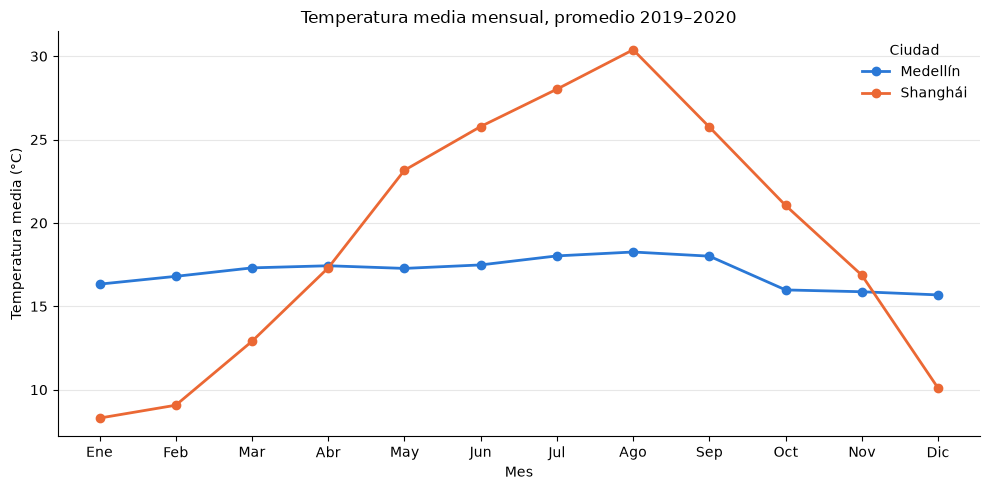

In [ ]:
# Grafico de lineas, con tempretria mensaual por cada cuidad

# Posiciones 1 a 12 en el eje X, una por mes
#agrupaciones por mes, escribimos 13 porque el 0 es tomado como posicion
x = np.arange(1, 13)

#delimitamos que vamos a mostrar en la graifca
fig, ax = plt.subplots(figsize=(10, 5))
#aqu delimitamos el recuadro pra las graficas  de cada pais 
ax.plot(x, temp_mes_med, color=COLOR_MED, linewidth=2, marker="o", label="Medellín")
ax.plot(x, temp_mes_sha, color=COLOR_SHA, linewidth=2, marker="o", label="Shanghái")

#delimitamos los titulos
ax.set_title("Temperatura media mensual, promedio 2019–2020")
#delimitamos los nombre de abajo o label en x
ax.set_xlabel("Mes")
#label en y
ax.set_ylabel("Temperatura media (°C)")
#marcas
ax.set_xticks(x, NOMBRES_MES)
#cuadricula 
ax.grid(axis="y", alpha=0.3)
#bordes de cuadro para grafica 
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Ciudad", frameon=False)

#imprimimos la tabla con plt
plt.tight_layout()
plt.show()

Hay mas fluctuacion de temperaturas en shangai que en medellin, lo cual tmb coincide con las estaciones, shangai muestra un clima de 30 grados en los meses de agosto, teneidno como punto mas alto del verano y un clima mas bajo en enero, lo que concuerda con el verano.

Medellin muestra tempraturas con muy poca variacion, pero se denota unos grados menos en octubre-diciembre lo que muestra lo que llaman epoca de lluvias de manera local. 

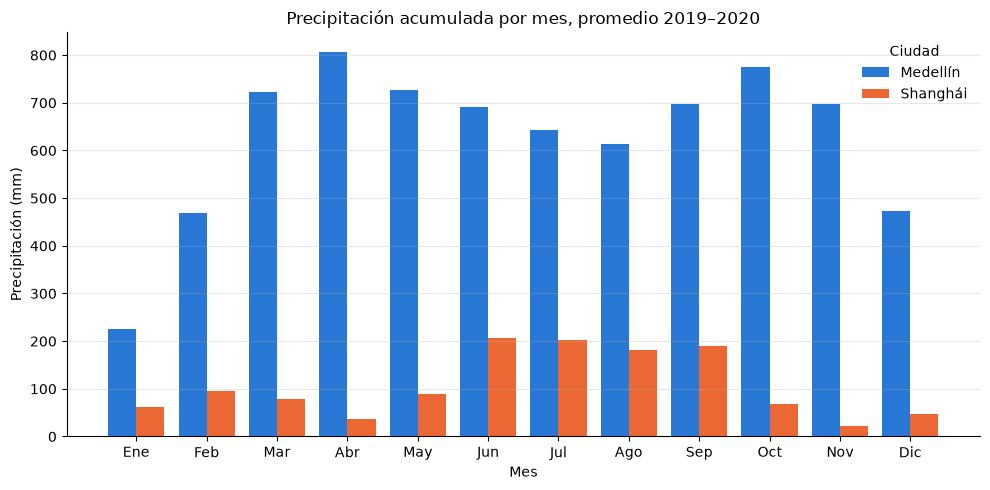

In [ ]:
# Celda 3: Barras agrupadas, precipitación mensual
# Ancho de cada barra: dos barras juntas ocupan 0.8 y queda espacio entre meses
ancho = 0.4

#tamaño de grafica 
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - ancho/2, lluvia_mes_med, width=ancho, color=COLOR_MED, label="Medellín")
ax.bar(x + ancho/2, lluvia_mes_sha, width=ancho, color=COLOR_SHA, label="Shanghái")

#titulo
ax.set_title("Precipitación acumulada por mes, promedio 2019–2020")
#label en x
ax.set_xlabel("Mes")
#label en y 
ax.set_ylabel("Precipitación (mm)")
#marcas
ax.set_xticks(x, NOMBRES_MES)
#cuadricula 
ax.grid(axis="y", alpha=0.3)
#bordes
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Ciudad", frameon=False)

plt.tight_layout()
plt.show()

Se denota que medellin tiene mas luvia en todos los menes comparada con shangai, aun con las estaciones, de denota mas mm de lluvia en el año, lo cual es caracterisitco de los paises tropicales. 

Sigue pareciendo un poco exagerados los MM de lluvia identificados en medellin, esto debe realizarse con estadisitcas reales, ya que se denota un poco fuera del margen normal

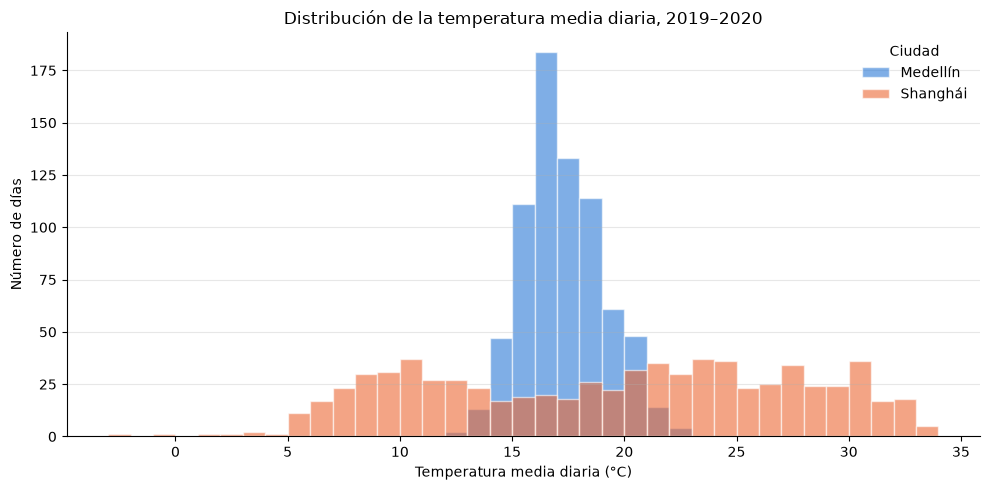

In [ ]:
#Celda 4: Histograma de temperatura media diaria

# Mismos intervalos de 1 °C para ambas ciudades, para que las barras sean comparables
#crreamos vordes, con arrage, agrupando la minima y maxima de ambas cuidades 
bordes = np.arange(np.floor(min(tmedia_med.min(), tmedia_sha.min())),
                   np.ceil(max(tmedia_med.max(), tmedia_sha.max())) + 1, 1)

#colores definidos para ambas cuidades 
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(tmedia_med, bins=bordes, color=COLOR_MED, alpha=0.6, edgecolor="white", label="Medellín")
ax.hist(tmedia_sha, bins=bordes, color=COLOR_SHA, alpha=0.6, edgecolor="white", label="Shanghái")

#titulo
ax.set_title("Distribución de la temperatura media diaria, 2019–2020")
#abel en x
ax.set_xlabel("Temperatura media diaria (°C)")
#lael en y 
ax.set_ylabel("Número de días")
#cuadricua
ax.grid(axis="y", alpha=0.3)
#margenes
ax.spines[["top", "right"]].set_visible(False)
#leyenda del grafico 
ax.legend(title="Ciudad", frameon=False)

plt.tight_layout()
plt.show()

Vemos que shangai muestra una gama mas variada de temperatura, posiblemente por las estaciones, mentras que medellin tiene mas dias con temperaturas similares. Esto lleva a pensar que shangai tiene estaiones, y aun en estas estaciones varia al temperatura. 

E. Interpreta los resultados
Responde la pregunta guía con evidencia de los cálculos y las gráficas:

Presenta al menos dos hallazgos, incluyendo una similitud y una diferencia entre las ciudades.
Sustenta cada hallazgo con valores, meses o conteos concretos.
Explica cómo el periodo común y los datos faltantes afectan la comparación.
No atribuyas causalidad a una asociación observada

Prediccion 
AUnque shangai es linea costera, y medellin esta por encima del nivel del mar, shangai presenta mas fluctuaciones de temperatura, al tener estaciones. 
Mientras que medellin, suele tener temperaturas muy similares todo el a;o.

Espero que
- Temperatura en medellin sea promedio de 22 grados centigrados (la media)
- Variacion en el año debe ser mas en shagai al tener estaciones
- La diferencia entre maxima y mina debe ser mayor en medellin, al tener un rango mas aplio y estar cerca al ecuador

En temas de lluvia 
- La precipitaciones deben ser maores en shangai que en medellin


Vamos a usar el rango de años del 1 de enero 2019-31 de dicme de 2020 a que tenemos datos de ambas cuidades
y se usaran las columnas: temperatura maxia, temperatura minima, y lluvia


Conclusiones
Hallazgo 1:
La temperatura promedio de medellin fue de 22,4 lo cual se acera mucho a la prediccion inicial para este caso. 
Nos encontramos con una novedad, ya que el promedeio de temperatura de shangai es similar a la de medellin,aun teniendo estaciones en este caso teniendo 22 grados de temperatrua promedio en shangai

Hallazgo 2
La desviacion estandar en medellin es de 1,8 en terminos de temperatura, teniendo una temperatura muy similar durante todo el año.mientras que en shangai es de 8.0 c lo que muestra una desviacion mayor, hablandonos de temperaturas mas variables en este caso. 
Si hablamos de cambios mas significativos en la temperatura de medellin, de denota una diferencia en menos grados en los meses de octurbe a enero, lo que coincide con las epocas de lluvia en la zona.
Con el slicing definido, y la temperatura umbral maxima de 25 grados, vemos que shangai tuvo mas de 228 dias calurosos mientras que medellin solo 110. Prediciemdo que el verano en shangai es mas fuerte que el clima mas alto de medellin.


Explica cómo el periodo común y los datos faltantes afectan la comparación.
En este ejercicio usamos un periodo corto, para que las fechas concidieras en ambos paises y lograr tener un punto de comparacion
Datos faltantes: Dentro del periodo analizado no se encoentraron valores faltantes ni fehcas duplicadas Quedando con 731 fechas posibles para analizar.
Calidad de los datos: Aunque contamos con datos de medellin, es cuestionable la realidad de esots datos en el DS ya que los promedios de lluvia son demasiado altos, comparados aun con shangai

